**Lab Exercise: SIFT – Scale Invariant Feature Transform**

**Karla Budimir**

SIFT (Scale-Invariant Feature Transform) is a cornerstone algorithm in computer vision
for detecting and describing local features in images. Its invariance to scale, rotation,
and partial affine transformations makes it ideal for tasks such as object recognition,
image matching, and 3D reconstruction.

1. Loading and Displaying an Image 

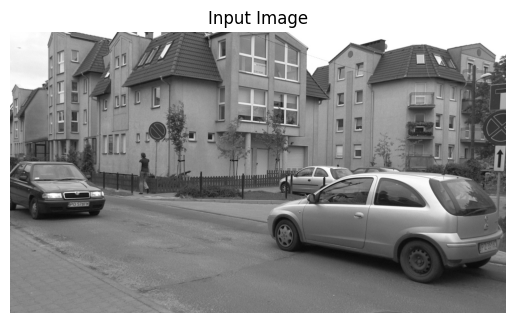

In [3]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

image_path = "PST_1920x1088_cam4.jpg"
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

plt.imshow(img, cmap='gray')
plt.title("Input Image")
plt.axis('off')
plt.show()

**Why is it sufficient (and preferred) to use grayscale images for feature
detection?**

Because working in grayscale simplifies the feature extraction process without sacrificing detection accuracy. 

Because SIFT relies on intensity changes and not color.

2. Detecting SIFT Keypoints 

In [5]:
sift = cv2.SIFT_create()
keypoints, descriptors = sift.detectAndCompute(img, None)
print(f"Number of keypoints detected: {len(keypoints)}")

Number of keypoints detected: 8204


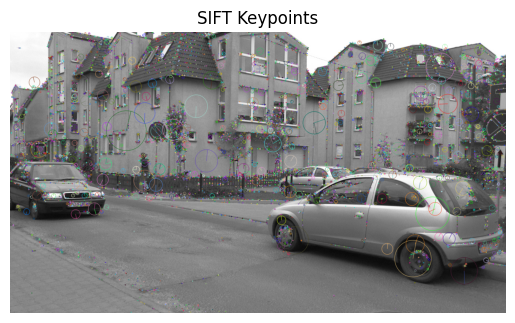

In [6]:
img_kp = cv2.drawKeypoints(img, keypoints, None,
flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(img_kp)
plt.title("SIFT Keypoints")
plt.axis('off')
plt.show()

**What kind of image structures tend to be detected as keypoints?**

In areas where the intensity gradient changes. I see a lot of corners circled.

3. Understanding the Descriptor Vector 

SIFT describes each keypoint using a 128-element vector that captures local image
gradient structure.

In [8]:
print(f"Descriptor shape: {descriptors.shape}")
print("First descriptor vector:\n", descriptors[0])

Descriptor shape: (8204, 128)
First descriptor vector:
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   3.
   0.   0.   0.   0.   0.   1.   8.  35.   1.   0.   0.   3.  16.  12.
   9.   9.   0.   0.  26.   3.   0.   0.   1.   1.   0.   0. 158.   8.
   0.   1.   3.  36.  23.  40.  15.   0.   0.   3.  71. 158.  30.  16.
   0.   0.   7.  12.  55. 158.   1.   0.  73.  18.   1.   1.  42.  14.
   0.   1. 158.  84.   3.  12.  14.   6.   4.  21.  43.  17.   4.  63.
 158.  96.   6.   8.   0.   0.   0.   3.  78. 158.  10.   0.  37.   6.
   0.   0.  56.  25.   1.   4. 158.  59.   1.   3.  11.   3.   1.   4.
  51.  14.   1.  12. 113.  29.   5.   5.   0.   0.   0.   6.  55.  71.
  12.   7.]


**What does the 128-element descriptor represent? Why is it always 128
elements?**

It represents the pattern of edges and directions of gradients around a keypoint.

It’s always 128 elements because of how SIFT looks at the patch around the keypoint. (4*4*8 directions)

(SIFT looks at a small square around the keypoint, splits it into 16 smaller squares, and for each one it counts how strong the edges are in 8 directions.)

4. Exploring Keypoint Attributes 

In [15]:
def unpack_octave(keypoint):
    octave = keypoint.octave & 255
    layer = (keypoint.octave >> 8) & 255
    if octave >= 128:
        octave = -((255 - octave + 1) & 255)
    scale = 1 / np.float64(1 << octave) if octave >= 0 else np.float64(1 << - octave)
    return octave, layer, scale

In [16]:
img = cv2.imread("PST_1920x1088_cam4.jpg", cv2.IMREAD_GRAYSCALE)
keypoints, descriptors = sift.detectAndCompute(img, None)

from collections import defaultdict
kp_data = []
for kp in keypoints:
    x, y = kp.pt
    angle = kp.angle
    size = kp.size
    octave, layer, scale = unpack_octave(kp)
    kp_data.append(((round(x, 2), round(y, 2)), angle, size, octave, layer,
round(scale, 4)))
    
location_dict = defaultdict(list)
for item in kp_data:
    location_dict[item[0]].append(item)
    
duplicates = {loc: pts for loc, pts in location_dict.items() if len(pts) > 1}
print(f"Number of duplicate keypoint positions: {len(duplicates)}")

Number of duplicate keypoint positions: 1328


**Why might multiple keypoints be detected at the same location?**

Because SIFT detects features at different scales or orientations so theduplicates are actually the same thing from a different perspective.

**What does the angle attribute mean for a keypoint?**

The angle is the direction of the dominant gradient around that keypoint.
It tells SIFT which way the feature is pointing and that is how SIFT can be rotation-invariant.

**What is the role of octave and scale in multi-scale feature detection?**

Octave - which level of the image pyramid the keypoint was found in 
 (Lower octaves = bigger image, higher octaves = downsampled images)

Scale - the size of the structure the keypoint represents 

Their role is the ability for SIFT to detect features that are the same even if the image is zoomed in or out.

5. Exploring SIFT Parameters 

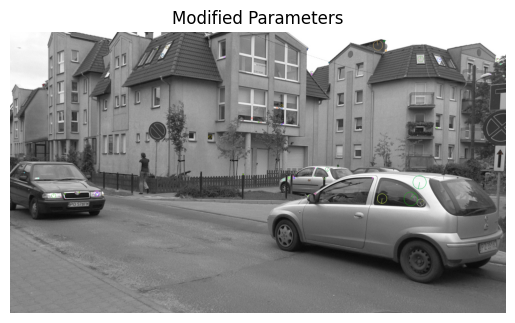

In [18]:
sift = cv2.SIFT_create(nfeatures=100, contrastThreshold=0.03, edgeThreshold=10,
sigma=1.2)
keypoints, descriptors = sift.detectAndCompute(img, None)
img_kp = cv2.drawKeypoints(img, keypoints, None,
flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(img_kp)
plt.title("Modified Parameters")
plt.axis('off')
plt.show()

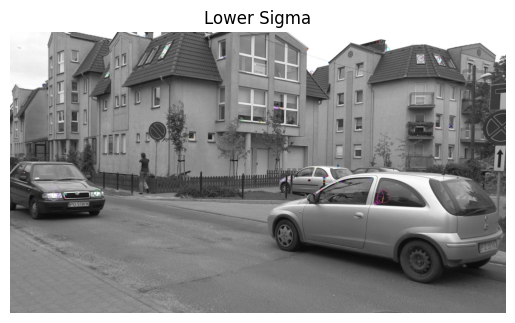

In [22]:
sift = cv2.SIFT_create(nfeatures=100, contrastThreshold=0.03, edgeThreshold=10, sigma=0.5)
keypoints, descriptors = sift.detectAndCompute(img, None)
img_kp = cv2.drawKeypoints(img, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(img_kp)
plt.title("Lower Sigma")
plt.axis('off')
plt.show()

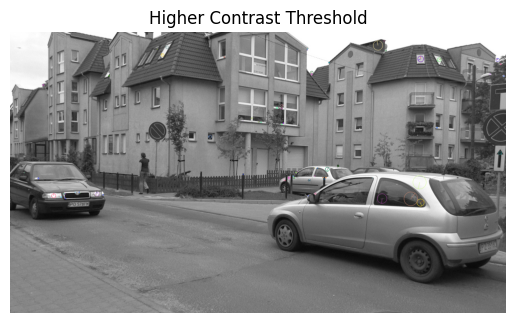

Number of keypoints: 100


In [23]:
sift = cv2.SIFT_create(nfeatures=100, contrastThreshold=0.1, edgeThreshold=10, sigma=1.2)
keypoints, descriptors = sift.detectAndCompute(img, None)
img_kp = cv2.drawKeypoints(img, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(img_kp)
plt.title("Higher Contrast Threshold")
plt.axis('off')
plt.show()
print("Number of keypoints:", len(keypoints))

**How does increasing contrastThreshold affect keypoint count?**

ContrastThreshold ignores weak features that don’t stand out from the background.
That way SIFT becomes pickier and only keeps "strong" features that are obvious.
That is the reason for much fewer keypoints.

**What kind of features appear at higher sigma values?**

Sigma controls how much the image is blurred before looking for keypoints
With higher sigma there is more blur and that's why it can only detect big and simpler structures... small features disappear.
Also fewer circles.

6. Real-Time SIFT via Webcam 

After running the code I took a screenshot.... 

In [ ]:
#cap = cv2.VideoCapture(0)
#sift = cv2.SIFT_create()

#while True:
   #ret, frame = cap.read()
    #gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    #keypoints, _ = sift.detectAndCompute(gray, None)
    #frame_kp = cv2.drawKeypoints(frame, keypoints, None,
#flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    #cv2.imshow('Live SIFT Keypoints', frame_kp)
    #if cv2.waitKey(1) & 0xFF == ord('q'):
        #break
        
#cap.release()
#cv2.destroyAllWindows()

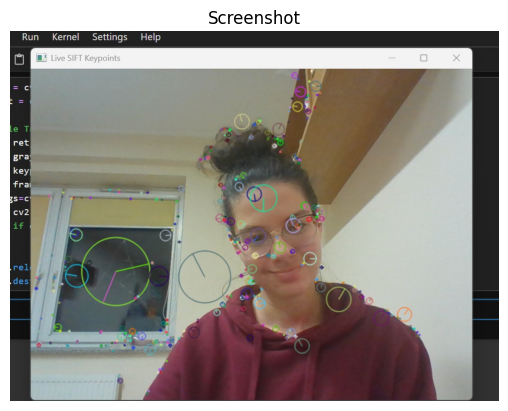

In [28]:
slika = cv2.imread("screen.jpg")  
slika_rgb = cv2.cvtColor(slika, cv2.COLOR_BGR2RGB)
plt.imshow(slika_rgb)
plt.axis('off')
plt.title("Screenshot")
plt.show()

**How stable are the detected keypoints in live video? What factors affect
stability?**

Keypoints in live video are mostly stable, but some appear or disappear between frames. 

Stability is affected by lighting, camera movement, zoom, and noise.

7. Matching Features Between Two Images 

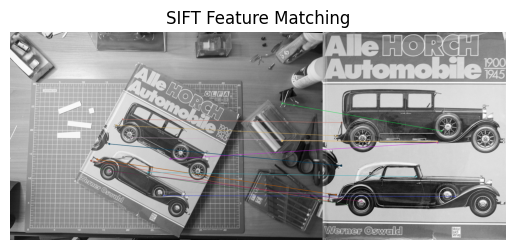

In [24]:
img1 = cv2.imread("img1.jpg", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("img2.jpg", cv2.IMREAD_GRAYSCALE)

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

bf = cv2.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

# Apply Lowe's ratio test
good = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good.append([m])
        
img_matches = cv2.drawMatchesKnn(img1, kp1, img2, kp2, good, None, flags=2)
plt.imshow(img_matches)
plt.title("SIFT Feature Matching")
plt.axis('off')
plt.show()

**What is the purpose of the ratio test? How does it filter poor matches?**

The purpose of the ratio test is to keep only good matches between keypoints. It compares the best match to the second-best match for each keypoint. If the best match is clearly better than the second-best then it stays and so on. Only strong obvious matches remain. 

8. Image Mosaicking – Building a Panorama

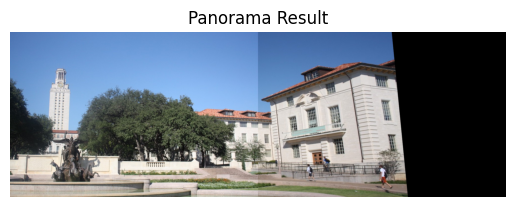

In [25]:
img_right = cv2.imread('obraz_prawy.jpg')
img1 = cv2.cvtColor(img_right, cv2.COLOR_BGR2GRAY)

img_left = cv2.imread('obraz_lewy.jpg')
img2 = cv2.cvtColor(img_left, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

matcher = cv2.BFMatcher()
matches = matcher.knnMatch(des1, des2, k=2)

good = []
for m in matches:
    if m[0].distance < 0.5 * m[1].distance:
        good.append(m)
matches = np.asarray(good)

if len(matches[:, 0]) >= 4:
    src = np.float32([kp1[m[0].queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    dst = np.float32([kp2[m[0].trainIdx].pt for m in matches]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
else:
    print("Not enough matches.")
    
# Warp and combine
dst_img = cv2.warpPerspective(img_right, H, (img_left.shape[1] +
img_right.shape[1], img_left.shape[0]))
dst_img[0:img_left.shape[0], 0:img_left.shape[1]] = img_left
cv2.imwrite("output.jpg", dst_img)
plt.imshow(cv2.cvtColor(dst_img, cv2.COLOR_BGR2RGB))
plt.title("Panorama Result")
plt.axis('off')
plt.show()

**What does the homography matrix represent in geometric terms?**

The homography matrix describes how to map points from one image to another. 

It tells us how to rotate, scale, translate or skew the first image so that it lines up with the second image.

**Why do we use warpPerspective?**

warpPerspective applies the homography to the image.

It changes the perspective of the first image so that it fits correctly over the second image. (takes care of the alignment)

**How could you improve blending at the overlap?**

I would find a tool to somehow blur or even completely wipe out the line which is now clearly seen between the images.
    
Another idea could be to adjust the colors or brightness of one image so it matches the other better.

9. Limitations of the SIFT method and possible improvements.......

It can be slow on large images, sometimes detects too many keypoints and struggles with very low-contrast or repetitive patterns. 

It can also have trouble in real-time applications like video.

**Some possible improvements:**

Applying better blending or filtering to reduce duplicate or weak keypoints
Combining SIFT with color or texture information to make matches more reliable